# COMP7015 Group Project – Topic 1: Plant Disease Classification

We classify tomato leaf images from the [PlantVillage dataset](https://github.com/spMohanty/PlantVillage-Dataset) into **healthy, early blight, leaf mold and spider mites** (two-spotted spider mite damage). We compare a custom CNN with attention, a fine-tuned ResNet18 and a fine-tuned Vision Transformer. Then we ask how robust they are: to the photo background, to colour, lighting and image quality, and to photos taken outside the lab. The photo backgrounds differ between the classes.

## 1. Setup & Configuration

The settings live in four dictionaries in `plantdisease/config.py`: `PATHS_CONFIG` (where data and results live), `DATA_CONFIG` (the PlantVillage protocol), `PLANTDOC_CONFIG` (the PlantDoc field photos) and `TRAIN_CONFIG` (training seeds, background-swap probability).

In [1]:
import os

import pandas as pd
import torch
import torchvision

from plantdisease.config import (
    DATA_CONFIG,
    PATHS_CONFIG,
    SHORT_NAMES,
    out_path,
    save_config,
)
from plantdisease.data.dataset import prepare
from plantdisease.data.download import download_plantvillage
from plantdisease.data.loaders import CachedDataset, make_loader, train_tf
from plantdisease.data.records import load_records
from plantdisease.device import USE_AMP, device
from plantdisease.plots import show_batch

save_config()  # all settings -> OUT_DIR/config.json

In [2]:
DATA_CONFIG

{'classes': ['Tomato___healthy',
  'Tomato___Bacterial_spot',
  'Tomato___Early_blight',
  'Tomato___Late_blight'],
 'img_size': 224,
 'split_seed': 62,
 'split_fractions': (0.7, 0.15),
 'num_workers': 2}

In [3]:
print("Device in use:", device, "| mixed precision:", USE_AMP)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

Device in use: cuda:0 | mixed precision: True
torch 2.15.0+cu132 | torchvision 0.29.2+cu132


## 2. Download the Data

We download the whole PlantVillage repository. We use the four tomato folders of `raw/color` (the RGB images used for training). We also use `raw/segmented`, the same photos with the background removed.

In [4]:
download_plantvillage()  # git clone of the whole repository, skipped if it exists
for kind in ("color", "segmented"):
    for class_name in DATA_CONFIG["classes"]:
        folder = f"raw/{kind}/{class_name}"
        n_images = len(os.listdir(os.path.join(PATHS_CONFIG["data_root"], folder)))
        print(f"{folder:60s} {n_images} images")

raw/color/Tomato___healthy                                   1591 images
raw/color/Tomato___Bacterial_spot                            2127 images
raw/color/Tomato___Early_blight                              1000 images
raw/color/Tomato___Late_blight                               1909 images
raw/segmented/Tomato___healthy                               1591 images
raw/segmented/Tomato___Bacterial_spot                        2127 images
raw/segmented/Tomato___Early_blight                          1000 images
raw/segmented/Tomato___Late_blight                           1909 images


## 3. Leaf Grouping & Label Verification

Every image must be assigned to a **physical leaf**, so that all photos of one leaf end up in the same split.

1. **Official metadata.** The image identifier from the file name is looked up in `leaf-map.json`, keeping only an entry of the image's own class. Most leaves are photographed four times.
2. **Official leaf ids only.** We use every photo of the four classes that has an official leaf id.
3. **Exclusion.** Photos without an official leaf id are excluded (`OUT_DIR/excluded_images.csv`): greenhouse photos whose leaf number can only be parsed from the file name, and photos without any leaf information.

In [5]:
# every photo of the four classes with its leaf id from leaf-map.json (plantdisease/data/records.py)
all_df = load_records()
# photos without an official leaf id (file-name leaf number only, or no leaf information) are excluded
all_df[all_df["source"] != "leaf map"].to_csv(
    out_path("excluded_images.csv"), index=False
)

pd.crosstab(all_df["class_name"], all_df["source"], margins=True).reindex(
    [*DATA_CONFIG["classes"], "All"]
)

source,excluded: no leaf information,file name,leaf map,All
class_name,,,,
Tomato___healthy,2,590,999,1591
Tomato___Bacterial_spot,0,0,2127,2127
Tomato___Early_blight,1,0,999,1000
Tomato___Late_blight,541,448,920,1909
All,544,1038,5045,6627


## 4. Image Cache

**Caching.** Decoding JPEGs and resizing them in every epoch is wasted work. Each image is decoded, converted to RGB and resized to 224×224 **once**, then stored as one `uint8` tensor in `cache/`. Training then only applies cheap tensor operations. The cache is rebuilt automatically if the image list or size changes.

In [6]:
# prepare() runs the whole data protocol: the photos with an official leaf id (Section 3),
# their images decoded + resized once, uint8 (N, 3, 224, 224), and the split (Section 5)
data = prepare()
df, images = data.df, data.images
print(f"Cached images: {tuple(images.shape)}, {images.numel() / 1e9:.2f} GB")

Cached images: (5045, 3, 224, 224), 0.76 GB


## 5. Leaf-Group Split & Leakage Audit

Within each class, the official leaf ids are shuffled with a fixed seed and split 70 / 15 / 15 into train / validation / test. All photos of one leaf follow its leaf id. The split seed is separate from the training seeds, so all models and seeds share **exactly the same split**. The audit asserts that no official leaf id appears in two splits.

In [7]:
# 70/15/15 split of the official leaf ids of every class; the audit is asserted inside make_split
print(
    f"Split seed: {DATA_CONFIG['split_seed']} | every official leaf id lies in exactly one split"
)

df[["path", "class_name", "leaf_id", "split"]].to_csv(
    out_path("split.csv"), index=False
)
counts = pd.crosstab(df["class_name"], df["split"], margins=True).reindex(
    [*DATA_CONFIG["classes"], "All"]
)[["train", "val", "test", "All"]]
counts["leaf ids"] = [
    *df.groupby("class_name")["leaf_id"]
    .nunique()
    .reindex(DATA_CONFIG["classes"])
    .tolist(),
    df.leaf_id.nunique(),
]
counts.to_csv(out_path("class_counts.csv"))
counts

Split seed: 62 | every official leaf id lies in exactly one split


split,train,val,test,All,leaf ids
class_name,,,,,
Tomato___healthy,699,152,148,999,250
Tomato___Bacterial_spot,1487,320,320,2127,532
Tomato___Early_blight,699,152,148,999,250
Tomato___Late_blight,644,136,140,920,230
All,3529,760,756,5045,1262


## 6. Preprocessing, Augmentation & Class Weights

The cached images are already resized to 224×224 (the whole photo, no crop). Every split is converted to float in [0, 1] and normalised with the ImageNet mean/std. The same preprocessing is used for all models, including the ViT.

**Training-only augmentation** must not change the symptoms:
- horizontal/vertical flips and **rotations by multiples of 90°**, because a leaf has no fixed orientation. These rotations are lossless and add no black corners, which matters because the background could carry class information (Section 4).
- a mild brightness/contrast jitter (±10%) for lighting changes. There is no hue/saturation change, so lesion colours (yellow halos, brown spots, mould) are preserved.

**Class balance.** Spider mites have about 1.7× more training images than the other classes. Rather than throwing data away, the CNNs use a **class-weighted cross-entropy loss** with weight $w_c = N / (K \cdot n_c)$, so errors on smaller classes cost more. Section 9 tests whether this helps. The ViT follows Zhouyang's protocol without class weights (notebook 03).

The transforms, the cached dataset and the loaders are defined in `plantdisease/data/`.

Class weights: {'healthy': 1.2619999647140503, 'Bacterial_spot': 0.5929999947547913, 'Early_blight': 1.2619999647140503, 'Late_blight': 1.3700000047683716}


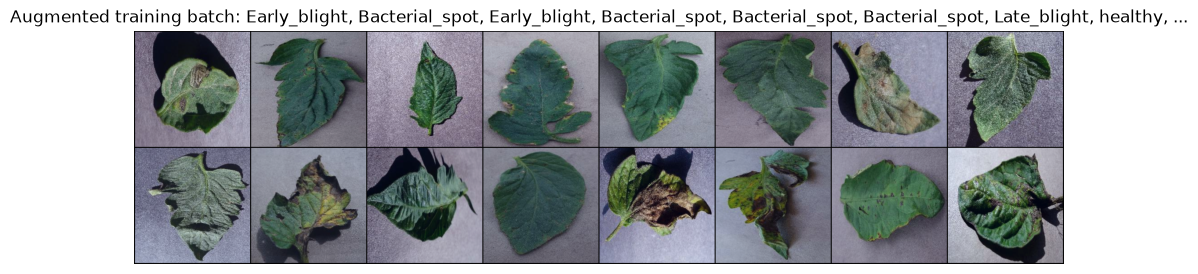

In [8]:
weights = data.class_weights  # w_c = N / (K * n_c)
print(
    "Class weights:",
    dict(zip(SHORT_NAMES, weights.numpy().round(3).tolist(), strict=True)),
)

# Visualise augmented training images
dataset = CachedDataset(images, data.labels, data.train_idx, train_tf)
x, y = next(iter(make_loader(dataset, 16, seed=0)))
show_batch(x, y, "Augmented training batch")

**Hand-over.** The following notebooks get exactly this data with the same call, `prepare()` (`plantdisease/data/dataset.py`), which takes a few seconds once the image cache exists. The split is saved to `OUT_DIR/split.csv`.